# K-means comparado con KNN, árboles y logística

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_completeness_v_measure)

SEED = 42                                   # reproducibilidad
np.set_printoptions(precision=3, suppress=True)
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

PALETA = ["#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b", "#17becf", "#7f7f7f"]
MARCAS = ["o", "s", "^", "D", "v", "P", "X", "*"]

def distancias_cuadradas(X, C):
    """Matriz n×k con ||x_i - c_j||²."""
    return ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)

def asignar(X, C):
    """Paso de ASIGNACIÓN: etiqueta del centro más cercano (y matriz de distancias²)."""
    d2 = distancias_cuadradas(X, C)
    return d2.argmin(axis=1), d2

def actualizar(X, etiquetas, k):
    """Paso de ACTUALIZACIÓN: cada centro es la media de los puntos de su grupo."""
    return np.vstack([X[etiquetas == j].mean(axis=0) for j in range(k)])

def inercia(X, etiquetas, C):
    """Función objetivo J (suma de cuadrados intra-grupo)."""
    return float(((X - C[etiquetas]) ** 2).sum())

def sombrear_regiones(ax, C, xlim, ylim, n=300):
    """Pinta las celdas de Voronoi de los centros C (regiones de asignación)."""
    k = len(C)
    xx, yy = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    Z = asignar(np.c_[xx.ravel(), yy.ravel()], C)[0].reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(k + 1) - 0.5, colors=PALETA[:k], alpha=0.08, zorder=0)
    if k > 1:
        ax.contour(xx, yy, Z, levels=np.arange(k - 1) + 0.5, colors="k",
                   linewidths=0.8, linestyles="--", zorder=1)

numpy 1.26.4 | pandas 2.0.3 | scikit-learn 1.9.1


## Carga de datos y calidad

In [4]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
try:
    pinguinos = pd.read_csv(URL)
except Exception as e:                                   # plan B: seaborn (requiere internet o caché local)
    print("No se pudo leer la URL directamente:", e)
    pinguinos = sns.load_dataset("penguins")

print("Dimensiones:", pinguinos.shape)
display(pinguinos.head())
pinguinos.info()

Dimensiones: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.100,18.700,181.000,"3,750.000",MALE
1,Adelie,Torgersen,39.500,17.400,186.000,"3,800.000",FEMALE
2,Adelie,Torgersen,40.300,18.000,195.000,"3,250.000",FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.700,19.300,193.000,"3,450.000",FEMALE


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [6]:
variables = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

faltantes = pinguinos.isna().sum().to_frame("n_faltantes")
faltantes["%"] = 100 * faltantes["n_faltantes"] / len(pinguinos)
display(faltantes)

print("Filas con algún valor numérico faltante:")
display(pinguinos[pinguinos[variables].isna().any(axis=1)])

,n_faltantes,%
species,0,0.000
island,0,0.000
bill_length_mm,2,0.581
bill_depth_mm,2,0.581
flipper_length_mm,2,0.581
body_mass_g,2,0.581
sex,11,3.198


Filas con algún valor numérico faltante:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


**Decisión sobre los datos faltantes.** K-means no admite valores faltantes (no se puede calcular una distancia con entradas ausentes). Hay 2 pingüinos sin **ninguna** medida numérica, que no aportan información: los eliminamos (*listwise deletion*). Imputar valores (por ejemplo con la media) sería arriesgado en clustering porque puede **fabricar estructura**: todos los imputados caerían exactamente sobre el centro de la nube. El sexo faltante (11 casos) no es problema porque no es una variable de entrada.

Separamos además lo que **se usa para entrenar** (`X_df`) de lo que **solo se usa para interpretar/validar** (`meta`).

In [8]:
datos = pinguinos.dropna(subset=variables).reset_index(drop=True)
X_df = datos[variables].copy()                     # entrada del modelo
meta = datos[["species", "island", "sex"]].copy()  # NO se usa para entrenar

print(f"Filas tras eliminar faltantes: {len(datos)} (se eliminaron {len(pinguinos) - len(datos)})")
print("Filas duplicadas:", datos.duplicated().sum())
display(meta["species"].value_counts().to_frame("n (solo para validar al final)").T)

Filas tras eliminar faltantes: 342 (se eliminaron 2)
Filas duplicadas: 0


species,Adelie,Gentoo,Chinstrap
n (solo para validar al final),151,123,68


## Exploración de datos (sin usar la especie)

Buscamos tres cosas relevantes para k-means: **escalas** de las variables, **asimetrías/valores atípicos** y **correlaciones**.

,count,mean,std,min,25%,50%,75%,max,asimetria
bill_length_mm,342.000,43.922,5.460,32.100,39.225,44.450,48.500,59.600,0.053
bill_depth_mm,342.000,17.151,1.975,13.100,15.600,17.300,18.700,21.500,-0.143
flipper_length_mm,342.000,200.915,14.062,172.000,190.000,197.000,213.000,231.000,0.346
body_mass_g,342.000,"4,201.754",801.955,"2,700.000","3,550.000","4,050.000","4,750.000","6,300.000",0.470


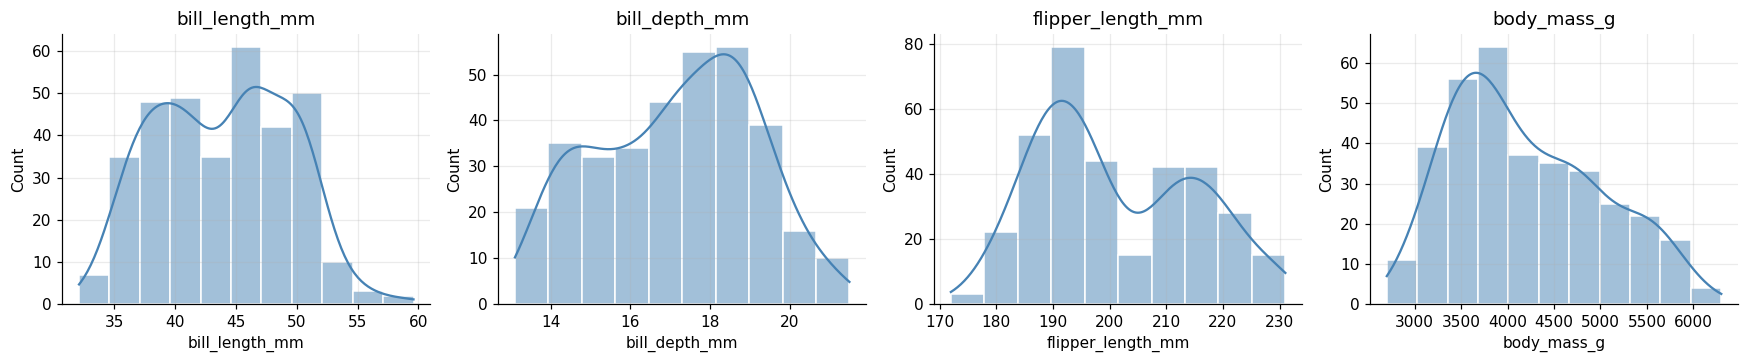

In [11]:
display(X_df.describe().T.assign(asimetria=X_df.skew()))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, variables):
    sns.histplot(X_df[col], kde=True, ax=ax, color="steelblue", edgecolor="white")
    ax.set_title(col)
plt.tight_layout(); plt.show()

Observaciones atípicas por variable (regla 1.5·IQR):
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0


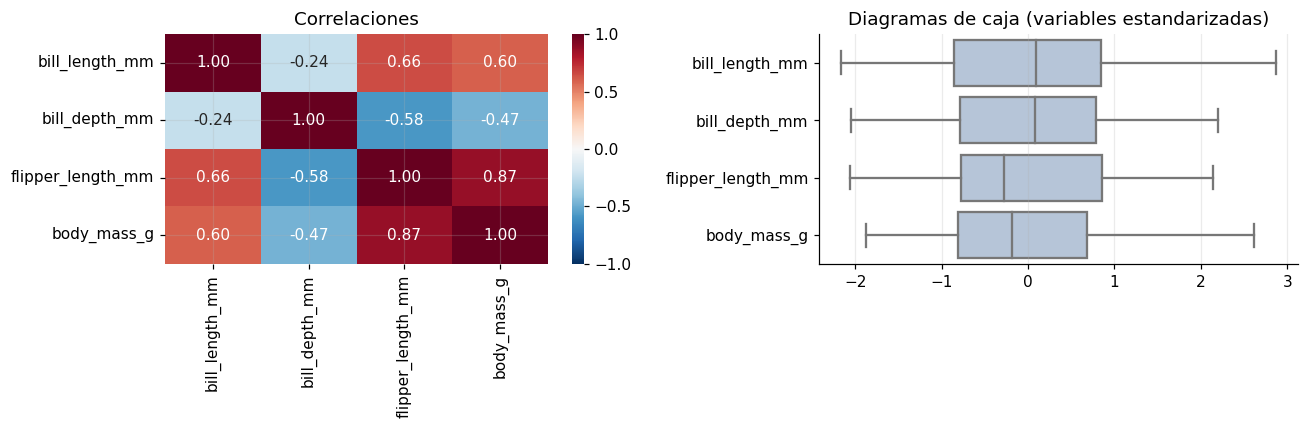

/Users/johnarredondo/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


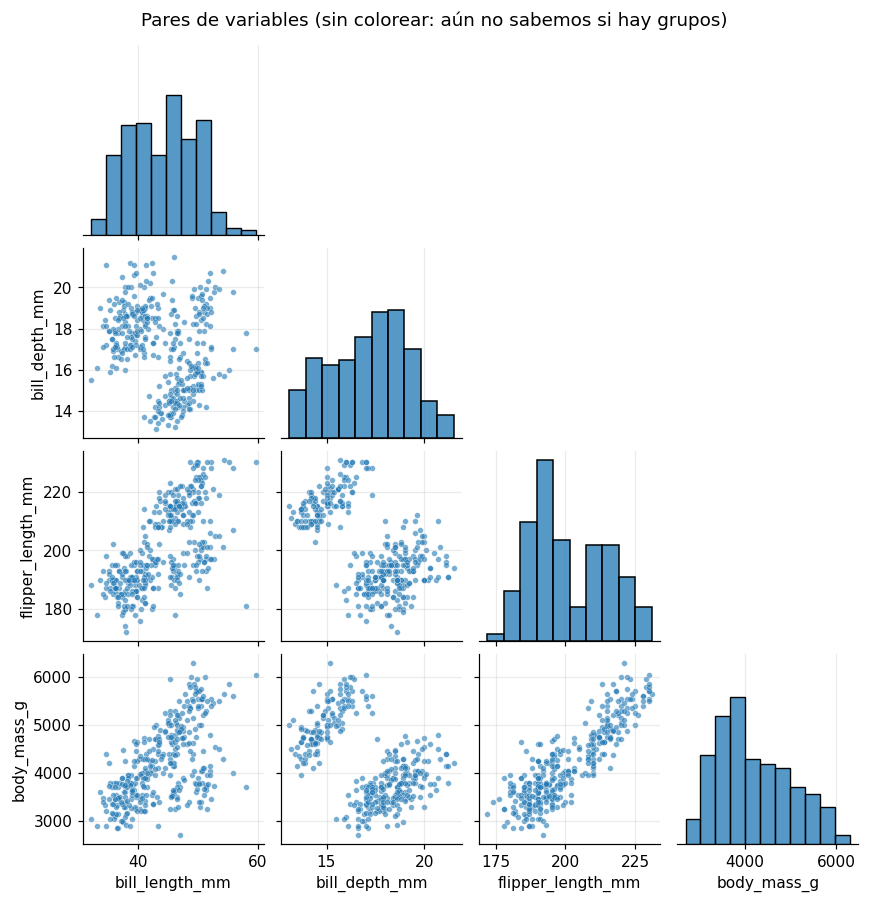

In [13]:
# Valores atípicos con la regla del rango intercuartílico (IQR)
q1, q3 = X_df.quantile(0.25), X_df.quantile(0.75)
iqr = q3 - q1
atipicos = ((X_df < q1 - 1.5 * iqr) | (X_df > q3 + 1.5 * iqr))
print("Observaciones atípicas por variable (regla 1.5·IQR):")
print(atipicos.sum().to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(X_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Correlaciones")
sns.boxplot(data=(X_df - X_df.mean()) / X_df.std(), orient="h", ax=ax[1], color="lightsteelblue")
ax[1].set_title("Diagramas de caja (variables estandarizadas)")
plt.tight_layout(); plt.show()

sns.pairplot(X_df, corner=True, plot_kws=dict(s=14, alpha=0.6), height=2.0)
plt.suptitle("Pares de variables (sin colorear: aún no sabemos si hay grupos)", y=1.02)
plt.show()

> **Hallazgos de la exploración.**
> * Las variables tienen escalas muy distintas: `body_mass_g` está en miles de gramos y `bill_depth_mm` en decenas de milímetros.
> * No hay observaciones atípicas extremas (la regla IQR no marca ninguna), de modo que no hace falta tratarlas.
> * Varias nubes de puntos muestran **separaciones o bultos**, lo que sugiere que hay estructura de grupos. Además `flipper_length_mm` y `body_mass_g` están muy correlacionadas (aportan información parecida).

## Escalado: por qué es indispensable aquí

Si no se escalan, cada variable aporta a la distancia euclídea en proporción a su **varianza**. Medimos cuánto aporta cada una a la distancia cuadrática media entre pares de pingüinos (que es proporcional a $\sigma_j^2/\sum_l\sigma_l^2$):

In [16]:
resumen_escala = pd.DataFrame({"media": X_df.mean(), "desv_est": X_df.std(), "min": X_df.min(), "max": X_df.max()})
resumen_escala["aporte a la distancia (sin escalar)"] = (X_df.var() / X_df.var().sum()).map("{:.4%}".format)
display(resumen_escala)

,media,desv_est,min,max,aporte a la distancia (sin escalar)
bill_length_mm,43.922,5.460,32.100,59.600,0.0046%
bill_depth_mm,17.151,1.975,13.100,21.500,0.0006%
flipper_length_mm,200.915,14.062,172.000,231.000,0.0307%
body_mass_g,"4,201.754",801.955,"2,700.000","6,300.000",99.9640%


Sin escalar, la **masa corporal** aporta prácticamente el 100 % de la distancia: k-means sería en la práctica un agrupamiento unidimensional por peso. Estandarizamos ($z=(x-\bar{x})/s$) para que las cuatro variables pesen lo mismo.

> **Importante para producción:** el escalador se **ajusta una sola vez** con los datos de entrenamiento y se reutiliza (con esa misma media y desviación) para cualquier dato nuevo. Por eso más adelante usamos un `Pipeline`.

In [18]:
escalador = StandardScaler().fit(X_df)
Z = escalador.transform(X_df)
Z_df = pd.DataFrame(Z, columns=variables)
display(Z_df.describe().loc[["mean", "std"]].T)

,mean,std
bill_length_mm,0.000,1.001
bill_depth_mm,-0.000,1.001
flipper_length_mm,-0.000,1.001
body_mass_g,0.000,1.001


##  ¿Cuántos grupos? Cuatro criterios

No existe un único criterio infalible. Calculamos, para $k=2,\dots,8$ (con 25 reinicios por cada $k$):

* **Inercia** (codo) · **Silueta media** (más alta es mejor) · **Calinski–Harabasz** (más alto es mejor) · **Davies–Bouldin** (más bajo es mejor) · y además el **estadístico gap**.

,inercia,silueta,calinski_harabasz,davies_bouldin
k,,,,
2,565.708,0.532,482.191,0.714
3,379.393,0.447,441.677,0.944
4,300.400,0.400,400.410,0.944
5,232.605,0.379,411.243,0.971
6,204.393,0.368,382.570,0.995
7,187.029,0.331,352.553,1.075
8,170.980,0.296,334.045,1.151


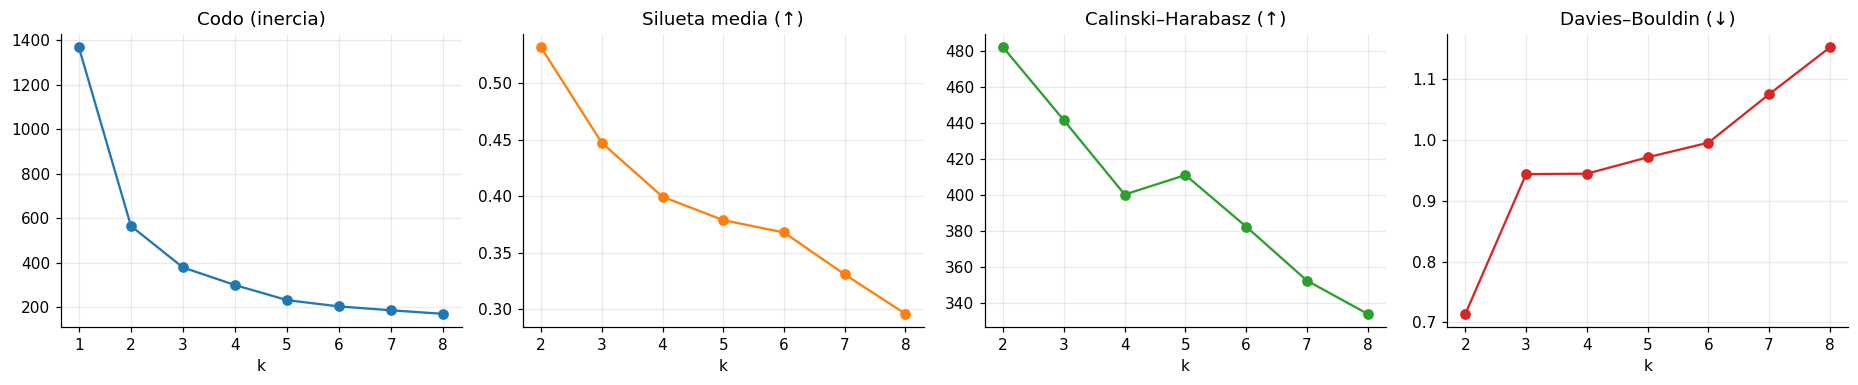

In [21]:
rango_k = list(range(2, 9))
modelos_k, filas = {}, []
for k in rango_k:
    km = KMeans(n_clusters=k, n_init=25, random_state=SEED).fit(Z)
    modelos_k[k] = km
    filas.append(dict(k=k, inercia=km.inertia_,
                      silueta=silhouette_score(Z, km.labels_),
                      calinski_harabasz=calinski_harabasz_score(Z, km.labels_),
                      davies_bouldin=davies_bouldin_score(Z, km.labels_)))
criterios = pd.DataFrame(filas).set_index("k")
inercia_k1 = float((Z ** 2).sum())                 # con k = 1 la inercia es la varianza total (TSS)
display(criterios)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
axes[0].plot([1] + rango_k, [inercia_k1] + criterios["inercia"].to_list(), "o-")
axes[0].set(title="Codo (inercia)", xlabel="k")
axes[1].plot(rango_k, criterios["silueta"], "o-", color="C1"); axes[1].set(title="Silueta media (↑)", xlabel="k")
axes[2].plot(rango_k, criterios["calinski_harabasz"], "o-", color="C2"); axes[2].set(title="Calinski–Harabasz (↑)", xlabel="k")
axes[3].plot(rango_k, criterios["davies_bouldin"], "o-", color="C3"); axes[3].set(title="Davies–Bouldin (↓)", xlabel="k")
plt.tight_layout(); plt.show()

### Estadístico gap

Compara la inercia observada con la que se esperaría en datos **sin estructura** (uniformes en el mismo rango). Se escoge el menor $k$ tal que $\text{Gap}(k)\ge\text{Gap}(k+1)-s_{k+1}$ (regla de Tibshirani et al.).

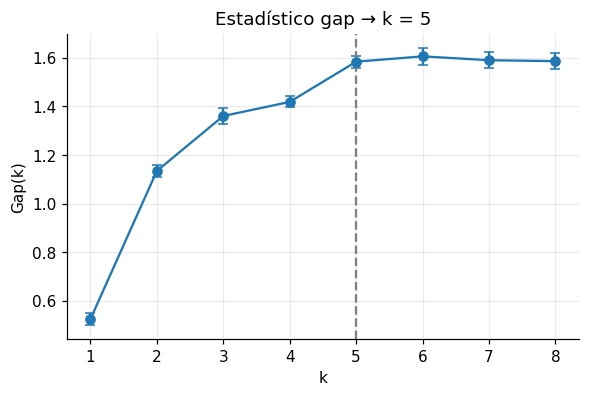

Gap(k) para k = 1..8: [0.525 1.135 1.361 1.419 1.584 1.606 1.59  1.586]
Regla de Tibshirani → k = 5


In [23]:
def estadistico_gap(Z, ks, B=20, n_init=5, seed=SEED):
    rng = np.random.default_rng(seed)
    lo, hi = Z.min(axis=0), Z.max(axis=0)
    gap, sk = [], []
    for k in ks:
        W = KMeans(k, n_init=n_init, random_state=seed).fit(Z).inertia_
        W_ref = [KMeans(k, n_init=n_init, random_state=seed)
                 .fit(rng.uniform(lo, hi, size=Z.shape)).inertia_ for _ in range(B)]
        logs = np.log(W_ref)
        gap.append(logs.mean() - np.log(W))
        sk.append(logs.std() * np.sqrt(1 + 1 / B))
    return np.array(gap), np.array(sk)

ks_gap = list(range(1, 9))
gap, sk = estadistico_gap(Z, ks_gap)
k_gap = next((k for i, k in enumerate(ks_gap[:-1]) if gap[i] >= gap[i + 1] - sk[i + 1]), ks_gap[-1])

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.errorbar(ks_gap, gap, yerr=sk, fmt="o-", capsize=3)
ax.axvline(k_gap, color="gray", ls="--")
ax.set(xlabel="k", ylabel="Gap(k)", title=f"Estadístico gap → k = {k_gap}")
plt.show()
print("Gap(k) para k = 1..8:", np.round(gap, 3))
print("Regla de Tibshirani → k =", k_gap)

### Diagramas de silueta

La silueta media resume todo en un número; el **diagrama de silueta** muestra cada observación (ordenada dentro de su grupo). Interesa que todos los grupos superen la media (línea roja), no tengan demasiados valores negativos y tengan anchos parecidos.

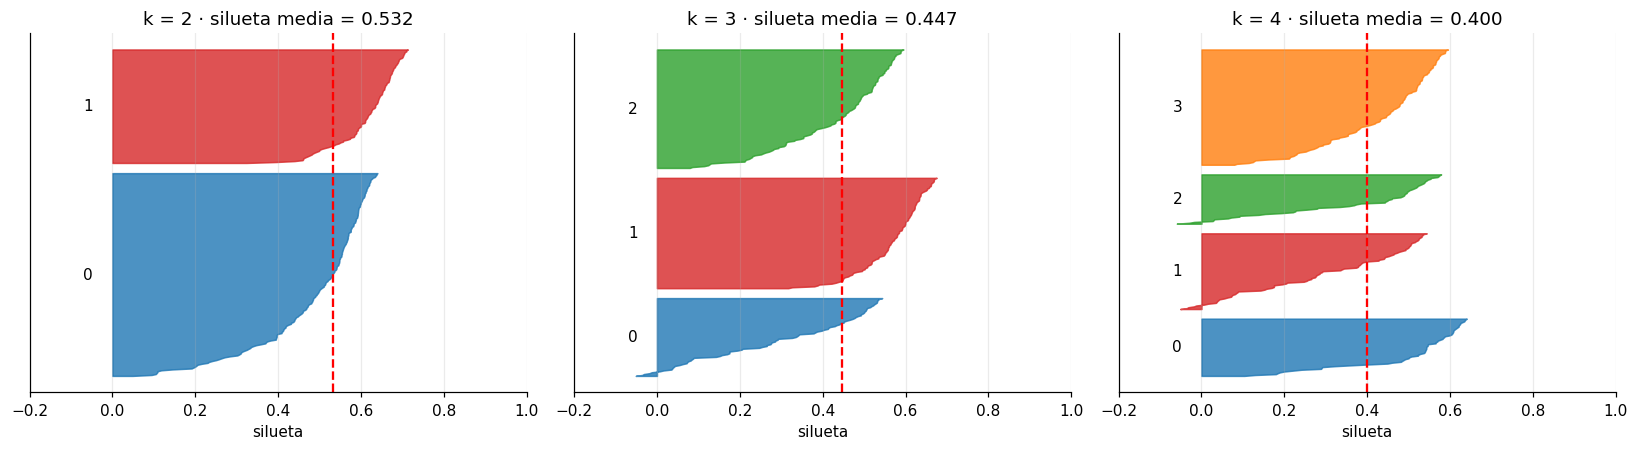

In [25]:
def diagrama_silueta(ax, Z, etiquetas, k):
    s = silhouette_samples(Z, etiquetas)
    y0 = 10
    for j in range(k):
        sj = np.sort(s[etiquetas == j])
        ax.fill_betweenx(np.arange(y0, y0 + len(sj)), 0, sj, color=PALETA[j], alpha=0.8)
        ax.text(-0.07, y0 + len(sj) / 2, str(j), va="center")
        y0 += len(sj) + 10
    ax.axvline(s.mean(), color="red", ls="--")
    ax.set(title=f"k = {k} · silueta media = {s.mean():.3f}", xlabel="silueta", xlim=(-0.2, 1), yticks=[])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, k in zip(axes, [2, 3, 4]):
    diagrama_silueta(ax, Z, modelos_k[k].labels_, k)
plt.tight_layout(); plt.show()

> **Lectura (importante).** Los criterios **no coinciden**, y eso es normal en datos reales: la silueta, Calinski–Harabasz y Davies–Bouldin prefieren $k=2$; el codo es poco nítido (la inercia cae mucho de $k=1$ a $k=2$, bastante de $k=2$ a $k=3$ y después de forma gradual); y la regla del estadístico gap (cuyo $\text{Gap}(k)$ sube rápido hasta $k=3$ y luego se aplana) termina escogiendo un $k$ mayor ($k=5$), una tendencia conocida de este criterio cuando los grupos no son perfectamente esféricos. La razón: dos especies (*Adelie* y *Chinstrap*) se parecen bastante entre sí y se separan de la tercera (*Gentoo*) con más claridad. Con $k=2$ obtenemos la separación más "limpia" y con $k=3$ una división más fina que es también razonable (y coincide con el número de especies, aunque ese dato no se usó para decidir).
>
> **Moraleja:** el $k$ no lo decide un solo número. Se combinan criterios, estabilidad (siguiente sección) e **interpretabilidad**. Aquí continuaremos con $k=3$ y compararemos con $k=2$ y $k=4$ en la sección 3.9.

## Estabilidad: ¿los grupos se sostienen si cambian los datos?

Nuestros 342 pingüinos son una **muestra**: con otra muestra de la misma población los grupos saldrían algo distintos. Una solución confiable debe **sobrevivir a ese cambio**; si los grupos se reorganizan por completo al cambiar unas pocas filas, probablemente reflejan ruido y no estructura real.

#### ¿Qué es el bootstrap?

Es un truco para simular "otra muestra" **sin recoger más datos**: se extraen $n$ filas **con reemplazo** de los datos originales. En cada remuestra algunas filas aparecen repetidas y otras no aparecen, de modo que cada remuestra es una versión plausible, ligeramente distinta, del conjunto de datos.

#### Procedimiento (para cada $k$, repetido 30 veces)

1. Crear dos remuestras bootstrap, A y B.
2. Ajustar k-means en A y otro k-means en B.
3. Usar cada modelo para asignar a **todos** los pingüinos originales (así ambas particiones cubren los mismos puntos).
4. Comparar las dos particiones con el **ARI** (índice de Rand ajustado): mide cuántas parejas de pingüinos quedan "juntas" o "separadas" de igual manera en ambas particiones, corregido por azar. No depende de cómo se numeren los grupos: **1 = particiones idénticas; ≈ 0 = parecido por puro azar**.

#### Cómo leer el resultado

ARI medio **alto** y poca dispersión → la solución es robusta. ARI **bajo o muy variable** → los grupos dependen de qué filas cayeron en la muestra: ese $k$ no es confiable.

,ARI medio,desv. est.,ARI mínimo
k,,,
2,1.000,0.002,0.988
3,0.911,0.061,0.811
4,0.764,0.161,0.532
5,0.896,0.058,0.764
6,0.838,0.094,0.602


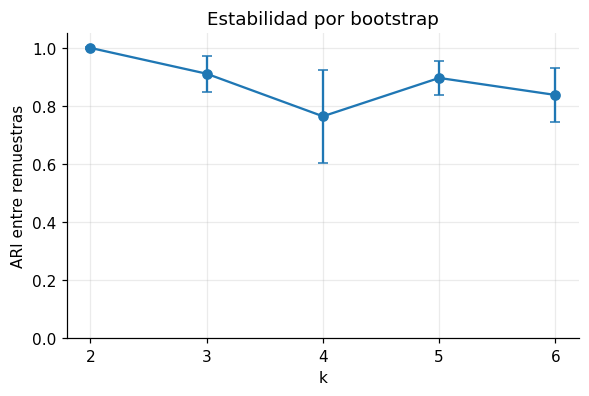

In [28]:
def estabilidad_bootstrap(Z, k, B=30, seed=SEED):
    rng = np.random.default_rng(seed)
    n, aris = len(Z), []
    for _ in range(B):
        m1 = KMeans(k, n_init=10, random_state=int(rng.integers(1_000_000))).fit(Z[rng.integers(0, n, n)])
        m2 = KMeans(k, n_init=10, random_state=int(rng.integers(1_000_000))).fit(Z[rng.integers(0, n, n)])
        aris.append(adjusted_rand_score(m1.predict(Z), m2.predict(Z)))
    return np.array(aris)

ks_est = [2, 3, 4, 5, 6]
est = {k: estabilidad_bootstrap(Z, k) for k in ks_est}
tabla_est = pd.DataFrame({"ARI medio": {k: v.mean() for k, v in est.items()},
                          "desv. est.": {k: v.std() for k, v in est.items()},
                          "ARI mínimo": {k: v.min() for k, v in est.items()}})
tabla_est.index.name = "k"
display(tabla_est)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.errorbar(ks_est, tabla_est["ARI medio"], yerr=tabla_est["desv. est."], fmt="o-", capsize=3)
ax.set(xlabel="k", ylabel="ARI entre remuestras", ylim=(0, 1.05), title="Estabilidad por bootstrap", xticks=ks_est)
plt.show()

> **Lectura.** Una estabilidad alta (ARI cerca de 1) indica que la partición es robusta. Con $k=2$ la solución es prácticamente idéntica en todas las remuestras (ARI ≈ 1), lo que concuerda con la silueta; con $k=3$ sigue siendo buena (ARI ≈ 0.9) pero con algo más de variación, y con $k=4$ es claramente la menos estable. La estabilidad no es necesariamente monótona en $k$ (aquí $k=5$ vuelve a subir), así que se interpreta junto con los demás criterios, no como una regla mecánica.

## Sensibilidad a la inicialización

#### ¿Por qué importa dónde arranca el algoritmo?

La inercia $J$ tiene muchos "valles" (mínimos locales). El algoritmo de Lloyd siempre **baja** por el valle más cercano a su punto de partida y no puede saltar a otro: dos corridas con centros iniciales distintos pueden terminar en soluciones **diferentes**, y algunas son peores (mayor $J$). A esto se le llama **sensibilidad a la inicialización**.

#### El experimento

Para medirla repetimos el ajuste muchas veces cambiando solo la semilla aleatoria:

* `aleatoria, n_init=1` y `k-means++, n_init=1`: **una sola** partida por corrida (200 corridas cada una).
* `k-means++, n_init=10`: en cada corrida, el algoritmo arranca 10 veces y **se queda con la de menor inercia** (100 corridas). Es la práctica recomendada.

#### Cómo leer el resultado

La línea punteada es la mejor solución conocida (la mejor de 100 reinicios). Idealmente casi todos los puntos caen sobre ella; los que quedan a la derecha son corridas atrapadas en un óptimo local peor. La columna `pct_alcanza_mejor` de la tabla da el porcentaje de corridas que llegan a la mejor solución.

,J_min,J_max,pct_alcanza_mejor
"aleatoria, n_init=1",379.393,486.297,52.500
"k-means++, n_init=1",379.393,486.297,57.000
"k-means++, n_init=10",379.393,381.092,99.000


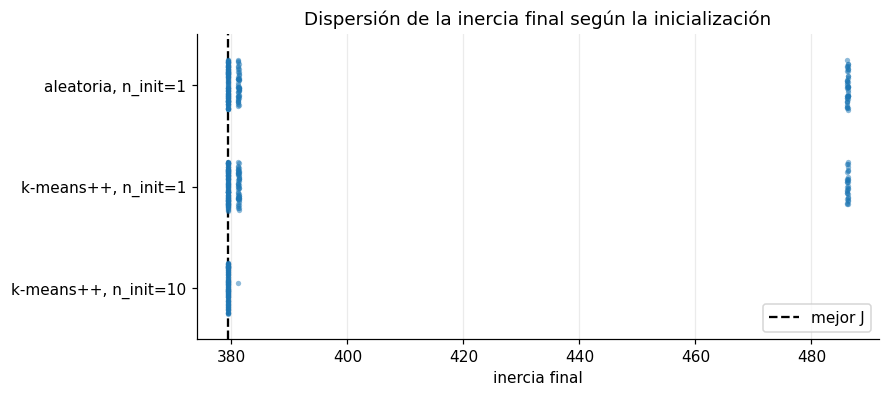

In [31]:
def inercias_corridas(init, n_init, n=200, k=3):
    return np.array([KMeans(k, init=init, n_init=n_init, random_state=s).fit(Z).inertia_ for s in range(n)])

J_ref = KMeans(3, n_init=100, random_state=SEED).fit(Z).inertia_     # mejor solución conocida (100 reinicios)
configs = {"aleatoria, n_init=1": ("random", 1), "k-means++, n_init=1": ("k-means++", 1),
           "k-means++, n_init=10": ("k-means++", 10)}
resultados_init = {nombre: inercias_corridas(*cfg, n=200 if cfg[1] == 1 else 100) for nombre, cfg in configs.items()}

tabla_init = pd.DataFrame({
    nombre: dict(J_min=J.min(), J_max=J.max(),
                 pct_alcanza_mejor=100 * np.mean(J <= J_ref * 1.0001))
    for nombre, J in resultados_init.items()}).T
display(tabla_init)

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.stripplot(data=pd.DataFrame(dict(J=np.concatenate(list(resultados_init.values())),
                                     config=np.repeat(list(resultados_init), [len(v) for v in resultados_init.values()]))),
              x="J", y="config", ax=ax, size=3.5, alpha=0.5, jitter=0.25)
ax.axvline(J_ref, color="k", ls="--", label="mejor J")
ax.set(xlabel="inercia final", ylabel="", title="Dispersión de la inercia final según la inicialización")
ax.legend(); plt.show()

> **Lectura.** Con **una sola** inicialización, aproximadamente la mitad de las corridas termina en un óptimo local peor que el mejor (k-means++ mejora un poco el porcentaje, pero no lo elimina). Con **varios reinicios** (`n_init=10` o más) casi siempre se alcanza la mejor solución. Por eso en el modelo final se usa k-means++ con `n_init=50` y una semilla fija (`random_state`) para que el resultado sea reproducible.

##  Modelo final

Se ajusta con un `Pipeline` (escalador + k-means), de modo que el mismo preprocesamiento se aplica automáticamente a datos nuevos. Como los números de grupo son **arbitrarios**, los reordenamos por masa corporal media creciente (para que "grupo 0" sea siempre el más liviano) y así los resultados sean comparables entre ejecuciones.

In [34]:
K_FINAL = 3
modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("kmeans", KMeans(n_clusters=K_FINAL, init="k-means++", n_init=50, max_iter=300,
                      tol=1e-4, random_state=SEED)),
]).fit(X_df)

km = modelo.named_steps["kmeans"]
print(f"Convergió en {km.n_iter_} iteraciones | inercia J = {km.inertia_:.2f} | "
      f"inercia/n = {km.inertia_ / len(X_df):.3f}")

# Reordenar etiquetas por masa corporal media creciente
centros_orig = modelo.named_steps["escalador"].inverse_transform(km.cluster_centers_)
orden = np.argsort(centros_orig[:, variables.index("body_mass_g")])
rango_etiqueta = np.empty(K_FINAL, dtype=int)
rango_etiqueta[orden] = np.arange(K_FINAL)

def etiquetar(X_nuevo):
    """Etiqueta ordenada (0 = grupo más liviano) para datos con las columnas de `variables`."""
    return rango_etiqueta[modelo.predict(X_nuevo[variables])]

datos["grupo"] = etiquetar(X_df)
print("Tamaño de los grupos:", datos["grupo"].value_counts().sort_index().to_dict())

Convergió en 5 iteraciones | inercia J = 379.39 | inercia/n = 1.109
Tamaño de los grupos: {0: 132, 1: 87, 2: 123}


## Perfilado e interpretación

**Perfilar** es describir cada grupo para entender qué significa: cuántos elementos tiene, cuáles son sus valores medios y **qué variables lo distinguen** de los demás. Es el paso que convierte "grupo 0, 1, 2" en algo interpretable.

Para ello hay que **volver a las unidades originales** (los centroides en el espacio estandarizado no se pueden leer directamente). Mostramos tamaños, centroides en unidades originales, el perfil en $z$-scores (un valor positivo significa "por encima del promedio global" y uno negativo "por debajo": sirve para ver rápido en qué se diferencia cada grupo) y las distribuciones por grupo.

,n,%,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
grupo 0,132,38.596,38.208,18.111,188.402,"3,584.659"
grupo 1,87,25.439,47.525,18.762,196.897,"3,902.011"
grupo 2,123,35.965,47.505,14.982,217.187,"5,076.016"


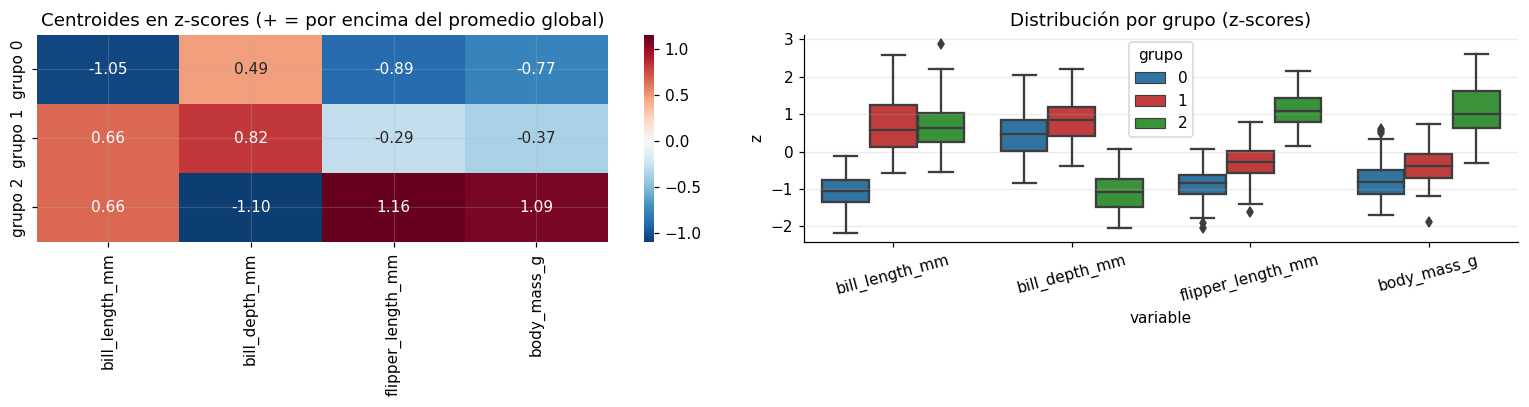

In [37]:
centros_ord = centros_orig[orden]                                   # centroides en unidades originales, ya ordenados
perfil3 = pd.DataFrame(centros_ord, columns=variables, index=[f"grupo {g}" for g in range(K_FINAL)])
perfil3.insert(0, "n", datos["grupo"].value_counts().sort_index().values)
perfil3.insert(1, "%", 100 * perfil3["n"] / perfil3["n"].sum())
display(perfil3)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
z_ord = km.cluster_centers_[orden]
sns.heatmap(pd.DataFrame(z_ord, columns=variables, index=perfil3.index), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("Centroides en z-scores (+ = por encima del promedio global)")
datos_largo = datos.melt(id_vars="grupo", value_vars=variables, var_name="variable", value_name="valor")
datos_largo["z"] = datos_largo.groupby("variable")["valor"].transform(lambda s: (s - s.mean()) / s.std())
sns.boxplot(data=datos_largo, x="variable", y="z", hue="grupo", palette=PALETA[:K_FINAL], ax=axes[1])
axes[1].set_title("Distribución por grupo (z-scores)"); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

### Visualización en 2D con PCA

Con 4 variables no se puede dibujar el agrupamiento directamente. Necesitamos **resumir** las 4 variables en 2 para poder hacer un gráfico.

#### ¿Qué es PCA?

El **análisis de componentes principales** construye ejes nuevos, llamados *componentes principales* (PC1, PC2, …). Cada uno es una **combinación** de las variables originales, y están ordenados por cuánta variabilidad de los datos capturan: PC1 captura la mayor posible, PC2 la mayor de lo que queda, etc. Quedarse con PC1 y PC2 da un mapa 2D que conserva la mayor parte de la información.

#### Cómo leer la salida

* **Varianza explicada:** porcentaje de la variabilidad total que conserva el mapa. Si es alto (aquí, cerca del 88 %), el mapa es fiel.
* **Tabla de cargas** (`components_`): dice cómo se forma cada eje. Por ejemplo, si PC1 tiene cargas positivas y grandes en aleta y masa corporal, PC1 se puede leer como un eje de "tamaño corporal".
* **Rombos blancos:** los centroides, proyectados al mismo mapa.

#### Dos advertencias

1. **PCA no forma parte de k-means.** El agrupamiento se hizo con las 4 variables estandarizadas; PCA solo sirve para *dibujar*.
2. Grupos que parecen **solaparse** en el mapa pueden estar separados en las dimensiones que el mapa no muestra (el ≈ 12 % de variabilidad restante).

Varianza explicada por PC1 y PC2: [0.688 0.193] → total 88.2%


,PC1,PC2
bill_length_mm,0.455,0.597
bill_depth_mm,-0.400,0.798
flipper_length_mm,0.576,0.002
body_mass_g,0.548,0.084


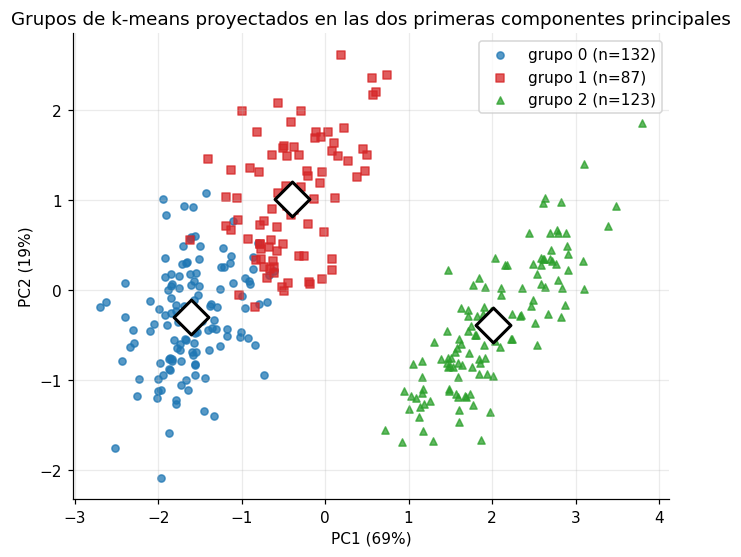

In [39]:
pca = PCA(n_components=2).fit(Z)
P = pca.transform(Z)
P_centros = pca.transform(km.cluster_centers_[orden])
print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_.round(3),
      f"→ total {pca.explained_variance_ratio_.sum():.1%}")
display(pd.DataFrame(pca.components_.T, index=variables, columns=["PC1", "PC2"]).round(3))

fig, ax = plt.subplots(figsize=(7, 5.5))
for g in range(K_FINAL):
    m = (datos["grupo"] == g).to_numpy()
    ax.scatter(P[m, 0], P[m, 1], s=22, alpha=0.75, color=PALETA[g], marker=MARCAS[g], label=f"grupo {g} (n={m.sum()})")
    ax.scatter(*P_centros[g], s=260, marker="D", facecolor="white", edgecolor="k", linewidth=2, zorder=5)
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
       title="Grupos de k-means proyectados en las dos primeras componentes principales")
ax.legend(); plt.show()

## Validación

### Validación interna (sin etiquetas)

In [42]:
s_i = silhouette_samples(Z, datos["grupo"])
print(f"Silueta media global: {s_i.mean():.3f}")
display(pd.DataFrame({"silueta media": pd.Series(s_i).groupby(datos["grupo"].to_numpy()).mean(),
                      "% con silueta < 0": pd.Series(s_i < 0).groupby(datos["grupo"].to_numpy()).mean() * 100}))

Silueta media global: 0.447


,silueta media,% con silueta < 0
0,0.431,0.000
1,0.301,5.747
2,0.568,0.000


### Validación externa (con la especie, que **nunca** se usó para entrenar)

#### ¿Qué significa "validar con una variable que no se usó"?

Hay dos tipos de validación:

* **Interna:** ¿los grupos son compactos y están separados *según los propios datos*? (silueta, etc.).
* **Externa:** ¿los grupos coinciden con una **referencia independiente**? Aquí esa referencia es la **especie**. Como la guardamos aparte (`meta`) y el modelo nunca la vio, compararla no es trampa: es como un examen cuyas respuestas el modelo no conocía.

#### ¿Por qué no calcular simplemente el accuracy?

Porque los números de grupo son **arbitrarios**: el "grupo 0" podría ser cualquiera de las especies. Se usan medidas que no dependen de cómo se numeren los grupos:

| Medida | Qué responde |
|---|---|
| **Tabla de contingencia** | Cuántos pingüinos de cada especie cayeron en cada grupo (filas: grupos; columnas: especies) |
| **ARI** | Qué tan parecida es la partición a la de las especies (1 = idéntica, ≈ 0 = azar) |
| **NMI** | Cuánta información comparten ambas particiones (0 a 1) |
| **Homogeneidad** | ¿Cada grupo contiene casi una sola especie? |
| **Completitud** | ¿Cada especie queda casi toda en un solo grupo? |
| **Medida V** | Promedio armónico de homogeneidad y completitud |
| **Pureza** | Fracción de pingüinos que pertenecen a la especie mayoritaria de su grupo |

> **Advertencia.** La especie es una referencia razonable, no "la verdad" del clustering: los grupos podrían reflejar otra estructura legítima (por ejemplo, tamaño o sexo). Y en problemas reales normalmente **no existe** tal referencia.

In [44]:
tab = pd.crosstab(datos["grupo"], meta["species"], rownames=["grupo k-means"], colnames=["especie"])
display(tab)

ari = adjusted_rand_score(meta["species"], datos["grupo"])
nmi = normalized_mutual_info_score(meta["species"], datos["grupo"])
hom, comp, vm = homogeneity_completeness_v_measure(meta["species"], datos["grupo"])
pureza = tab.max(axis=1).sum() / tab.values.sum()
display(pd.Series(dict(ARI=ari, NMI=nmi, homogeneidad=hom, completitud=comp, medida_V=vm, pureza=pureza),
                  name="valor").to_frame())

# Pingüinos "mal ubicados": su especie no es la mayoritaria de su grupo
especie_mayoritaria = tab.idxmax(axis=1)
mal = datos[datos["species"] != datos["grupo"].map(especie_mayoritaria)]
print(f"Pingüinos cuya especie no es la mayoritaria de su grupo: {len(mal)} de {len(datos)}")
display(mal[["species", "island", "sex"] + variables + ["grupo"]].head(10))

especie,Adelie,Chinstrap,Gentoo
grupo k-means,,,
0,127,5,0
1,24,63,0
2,0,0,123


,valor
ARI,0.793
NMI,0.786
homogeneidad,0.798
completitud,0.773
medida_V,0.786
pureza,0.915


Pingüinos cuya especie no es la mayoritaria de su grupo: 29 de 342


,species,island,sex,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,grupo
8,Adelie,Torgersen,NaN,42.000,20.200,190.000,"4,250.000",1
16,Adelie,Torgersen,MALE,42.500,20.700,197.000,"4,500.000",1
18,Adelie,Torgersen,MALE,46.000,21.500,194.000,"4,200.000",1
42,Adelie,Dream,MALE,44.100,19.700,196.000,"4,400.000",1
48,Adelie,Dream,MALE,42.300,21.200,191.000,"4,150.000",1
52,Adelie,Biscoe,MALE,42.000,19.500,200.000,"4,050.000",1
60,Adelie,Biscoe,MALE,41.300,21.100,195.000,"4,400.000",1
68,Adelie,Torgersen,MALE,41.800,19.400,198.000,"4,450.000",1
72,Adelie,Torgersen,MALE,45.800,18.900,197.000,"4,150.000",1
74,Adelie,Torgersen,MALE,42.800,18.500,195.000,"4,250.000",1


**Otras variables de interpretación** (tampoco usadas para entrenar): el **sexo** y la **isla**. Los machos son en promedio más grandes que las hembras en las tres especies (dimorfismo sexual), lo que puede mezclar el efecto "especie" con el efecto "sexo" en las medidas.

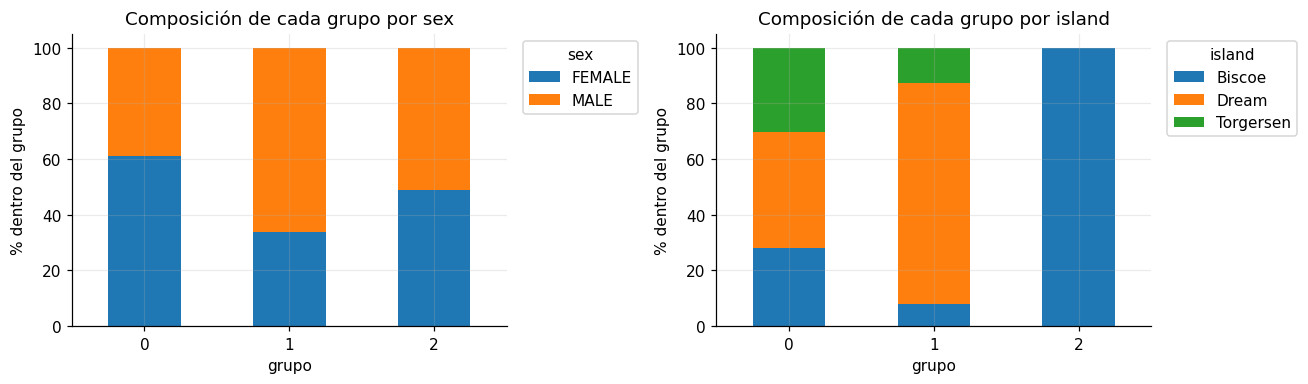

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, col in zip(axes, ["sex", "island"]):
    pd.crosstab(datos["grupo"], meta[col], normalize="index").mul(100).plot.bar(stacked=True, ax=ax, rot=0)
    ax.set(ylabel="% dentro del grupo", xlabel="grupo", title=f"Composición de cada grupo por {col}")
    ax.legend(title=col, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

> **Lectura.** Sin haber visto nunca la especie, k-means separa a la perfección a *Gentoo* (grupo 2) y divide a las otras dos especies en dos grupos que solo coinciden en parte con ellas (ARI ≈ 0.8, pureza ≈ 0.9). Los errores se concentran en el solapamiento entre *Adelie* y *Chinstrap*: el grupo 1 reúne a casi todos los *Chinstrap* pero también a 24 *Adelie* (todos machos, salvo uno de sexo desconocido), que son más grandes y de picos más profundos (dimorfismo sexual; ver el gráfico de composición por sexo). Recuerde que en un proyecto real normalmente **no habrá una especie** con la cual validar: por eso son tan importantes los criterios internos, la estabilidad y la interpretación con expertos del dominio.

## ¿Qué habría pasado si…? Efecto de las decisiones técnicas

Comparamos el modelo final con variantes (solo con fines pedagógicos, usando la especie como referencia externa). La silueta se calcula siempre en el espacio estandarizado para que sea comparable. Dos de las variantes son métodos que quizá no conozca; antes de verlas, una explicación breve.

### ¿Qué es una mezcla gaussiana?

K-means asigna cada punto a **un único grupo** (asignación "dura") y, sin decirlo, supone que los grupos son nubes **redondas** de tamaño parecido. La **mezcla gaussiana** (*Gaussian Mixture Model*, GMM) es un modelo probabilístico que relaja esos supuestos:

* Supone que los datos salen de **$k$ distribuciones normales** ("campanas" en varias dimensiones). Cada una tiene su propio **centro** (media), su propia **forma y tamaño** (matriz de covarianza) y un **peso** (qué proporción de los datos genera).
* Para cada punto calcula la **probabilidad de pertenecer a cada grupo** (asignación "blanda"): por ejemplo, 70 % grupo A y 30 % grupo B. Un punto en la frontera entre dos nubes queda con probabilidades repartidas, en vez de forzarlo a un solo grupo.
* Se ajusta con el algoritmo **EM**, que se parece mucho al de Lloyd: el *paso E* calcula probabilidades (análogo a **asignar**) y el *paso M* recalcula medias, covarianzas y pesos (análogo a **actualizar**).

El parámetro `covariance_type` controla la forma permitida de cada campana:

| `covariance_type` | Forma de cada grupo | Comentario |
|---|---|---|
| `"spherical"` | Nube **redonda**, con tamaño propio | Es el análogo probabilístico de k-means |
| `"full"` | **Elipse** de cualquier forma y orientación | La más flexible; útil cuando las variables están correlacionadas dentro de cada grupo (aquí, aleta y masa) |

### ¿Y el método jerárquico de Ward?

Empieza con cada pingüino como su propio grupo y, paso a paso, **fusiona los dos grupos cuya unión aumenta menos la varianza intra-grupo**, hasta quedar con $k$ grupos. No necesita centros iniciales (es determinista) ni supone grupos estrictamente esféricos.

### La comparación

Las columnas: `ARI_especie` y `NMI_especie` (concordancia con la especie, más alto es mejor) y `silueta_Z` (separación interna en el espacio estandarizado).

In [49]:
variantes = {}
variantes["k-means SIN escalar (k=3)"] = KMeans(3, n_init=50, random_state=SEED).fit_predict(X_df.to_numpy())
for k in (2, 3, 4):
    variantes[f"k-means escalado (k={k})" + (" ← final" if k == 3 else "")] = \
        KMeans(k, n_init=50, random_state=SEED).fit_predict(Z)
variantes["Mezcla gaussiana, cov. completa (k=3)"] = GaussianMixture(3, covariance_type="full", n_init=10, random_state=SEED).fit_predict(Z)
variantes["Mezcla gaussiana, cov. esférica (k=3)"] = GaussianMixture(3, covariance_type="spherical", n_init=10, random_state=SEED).fit_predict(Z)
variantes["Jerárquico Ward (k=3)"] = AgglomerativeClustering(3, linkage="ward").fit_predict(Z)

comparacion = pd.DataFrame({
    nombre: dict(ARI_especie=adjusted_rand_score(meta["species"], lab),
                 NMI_especie=normalized_mutual_info_score(meta["species"], lab),
                 silueta_Z=silhouette_score(Z, lab))
    for nombre, lab in variantes.items()}).T
display(comparacion.sort_values("ARI_especie", ascending=False))

,ARI_especie,NMI_especie,silueta_Z
"Mezcla gaussiana, cov. completa (k=3)",0.960,0.935,0.455
Jerárquico Ward (k=3),0.916,0.901,0.454
"Mezcla gaussiana, cov. esférica (k=3)",0.873,0.838,0.459
k-means escalado (k=3) ← final,0.793,0.786,0.447
k-means escalado (k=2),0.655,0.767,0.532
k-means escalado (k=4),0.637,0.704,0.400
k-means SIN escalar (k=3),0.319,0.401,0.248


> **Lecturas.**
> * **Escalado:** sin escalar, k-means agrupa casi solo por masa corporal y el ARI cae a ≈ 0.3, frente a ≈ 0.8 con escalado: es el error de preprocesamiento más frecuente y más costoso.
> * **Elección de $k$:** con $k=2$ la silueta es la mejor (grupos "más limpios") pero se fusionan dos especies; con $k=4$ se subdivide más y la concordancia con las especies baja. Que la silueta sea máxima no significa que la partición responda mejor a la pregunta de negocio o científica.
> * **Otros algoritmos:** la mezcla gaussiana de covarianza completa (grupos elípticos de distinta forma y orientación) ajusta aquí claramente mejor (ARI ≈ 0.96 frente a ≈ 0.79), y el método jerárquico de Ward también supera a k-means. Esto recuerda los **supuestos implícitos de k-means**: grupos aproximadamente esféricos y de tamaño similar. Con covarianza esférica la mezcla gaussiana es, en teoría, el análogo probabilístico de k-means, aunque aquí también mejora el resultado porque permite grupos de distinto tamaño y asigna con probabilidades.

### Asignación "blanda": lo que k-means no puede decir

K-means entrega una etiqueta y nada más. La mezcla gaussiana, además, indica **qué tan segura** es esa asignación. Veamos los pingüinos con la asignación **más incierta** (probabilidad máxima más baja) y comparemos con lo que dice k-means.

In [51]:
gmm = GaussianMixture(3, covariance_type="full", n_init=10, random_state=SEED).fit(Z)
prob = gmm.predict_proba(Z)                                   # probabilidad de pertenecer a cada componente
print(f"Pingüinos con probabilidad máxima > 95 %: {np.mean(prob.max(axis=1) > 0.95):.1%}")

dudosos = np.argsort(prob.max(axis=1))[:8]                    # los 8 más inciertos
tabla_prob = pd.DataFrame(prob[dudosos], columns=[f"P(componente {j})" for j in range(3)])
tabla_prob.insert(0, "especie real", meta["species"].to_numpy()[dudosos])
tabla_prob.insert(1, "grupo k-means", datos["grupo"].to_numpy()[dudosos])
display(tabla_prob)

Pingüinos con probabilidad máxima > 95 %: 96.2%


,especie real,grupo k-means,P(componente 0),P(componente 1),P(componente 2)
0,Chinstrap,0,0.430,0.000,0.570
1,Chinstrap,0,0.602,0.000,0.398
2,Chinstrap,1,0.321,0.000,0.679
3,Adelie,1,0.274,0.000,0.726
4,Adelie,1,0.780,0.000,0.220
5,Chinstrap,0,0.821,0.000,0.179
6,Chinstrap,1,0.111,0.000,0.889
7,Chinstrap,1,0.096,0.000,0.904


> **Lectura.** La gran mayoría de los pingüinos se asigna con probabilidad casi 1, pero hay unos pocos "dudosos" con probabilidades repartidas entre dos componentes: son justamente los que están en la zona de solapamiento entre *Adelie* y *Chinstrap*, donde k-means debe forzar una decisión. (La numeración de los componentes de la mezcla es arbitraria, igual que la de los grupos de k-means; aquí lo importante es que dos de las tres probabilidades suman casi 1, es decir, la duda está entre dos grupos.) Esa información de **incertidumbre** es una ventaja de los modelos probabilísticos.

##  Datos nuevos y despliegue

Para asignar un pingüino nuevo basta con `modelo.predict`, porque el `Pipeline` aplica el **mismo escalado** del entrenamiento. Además, la distancia al centroide permite detectar observaciones **atípicas** (muy lejos de todo grupo), un aviso de que el modelo quizá no sea apropiado para ese caso. Como umbral usamos el percentil 99 de las distancias de entrenamiento.

In [54]:
dist_train = modelo.transform(X_df)[np.arange(len(X_df)), modelo.predict(X_df)]   # distancia (en z) al propio centroide
umbral = np.percentile(dist_train, 99)

nuevos = pd.DataFrame({
    "bill_length_mm":    [39.0, 48.5, 50.0, 60.0],
    "bill_depth_mm":     [18.5, 15.0, 15.5, 25.0],
    "flipper_length_mm": [190, 215, 220, 250],
    "body_mass_g":       [3600, 5000, 5400, 9000],
}, index=["nuevo 1", "nuevo 2", "nuevo 3", "nuevo 4 (extremo)"])

dist_n = modelo.transform(nuevos)
salida = nuevos.copy()
salida["grupo"] = etiquetar(nuevos)
salida["distancia_a_su_centroide"] = dist_n[np.arange(len(nuevos)), modelo.predict(nuevos)]
salida["¿atípico? (> p99 entrenamiento)"] = salida["distancia_a_su_centroide"] > umbral
print(f"Umbral (percentil 99 de distancias de entrenamiento): {umbral:.3f}")
display(salida)

Umbral (percentil 99 de distancias de entrenamiento): 2.032


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,grupo,distancia_a_su_centroide,¿atípico? (> p99 entrenamiento)
nuevo 1,39.000,18.500,190,3600,0,0.271,False
nuevo 2,48.500,15.000,215,5000,2,0.258,False
nuevo 3,50.000,15.500,220,5400,2,0.694,False
nuevo 4 (extremo),60.000,25.000,250,9000,2,7.780,True


**Guardar y reutilizar el modelo.** Se guarda el `Pipeline` completo (escalador + k-means) junto con el orden de etiquetas, y se comprueba que al recargarlo se obtienen las mismas asignaciones.

In [56]:
import joblib, tempfile, os
ruta = os.path.join(tempfile.gettempdir(), "modelo_kmeans_pinguinos.joblib")
joblib.dump(dict(modelo=modelo, rango_etiqueta=rango_etiqueta, variables=variables, k=K_FINAL), ruta)

cargado = joblib.load(ruta)
etiq_recargadas = cargado["rango_etiqueta"][cargado["modelo"].predict(X_df[cargado["variables"]])]
print("Modelo guardado en:", ruta)
print("¿Las asignaciones tras recargar coinciden?", np.array_equal(etiq_recargadas, datos["grupo"].to_numpy()))

Modelo guardado en: /var/folders/kh/8_x8gdnd71qdr1yk_k0xnffr0000gn/T/modelo_kmeans_pinguinos.joblib
¿Las asignaciones tras recargar coinciden? True


##  ¿Se pueden comparar KNN, árboles de decisión, regresión logística y k-means?

Ya conocemos los siguientes modelos: KNN, los árboles de decisión y la regresión logística. Tomando los datos de los pingüinos podemos ponerlos al lado de k-means para "compararlos" en términos de efectividad, pero **no resuelven el mismo problema**:

| | KNN | Árbol de decisión | Regresión logística | K-means |
|---|---|---|---|---|
| ¿Usa la especie para aprender? | **Sí** (supervisado) | **Sí** (supervisado) | **Sí** (supervisado) | **No** (no supervisado) |
| ¿Qué entrega? | Una especie predicha | Una especie predicha | Una especie predicha (con probabilidades) | Un número de grupo, sin nombre |
| ¿Paramétrico? | No | No | **Sí** | Sí ($k$ centroides) |
| ¿Qué se guarda tras entrenar? | Todos los datos | Reglas | **Coeficientes** | Centroides |
| Forma de las fronteras | Irregulares | Paralelas a los ejes | **Lineales** | Lineales (Voronoi) |
| ¿Necesita escalar? | Sí | No | Conviene (ver abajo) | Sí |

Por eso hay que cuidar la **justicia de la comparación**:

1. **Los tres modelos supervisados reciben información extra** (las etiquetas). Que le ganen a k-means no dice que sean "mejores algoritmos", más bien da cuenta o  mide **cuánto vale tener etiquetas**.
2. **Evaluación honesta.** A los modelos supervisados se les evalúa con **validación cruzada**, predicen pingüinos que no vieron al entrenar.
3. **Los números de grupo de k-means no son especies.** Para poder calcular accuracy o F1 hace falta un *mapeo*: dentro de cada partición de entrenamiento, a cada grupo se le asigna su **especie mayoritaria**, este es un uso mínimo de las etiquetas, hecho solo con los datos de entrenamiento de cada partición, nunca con los de prueba.
4. **El ARI se puede calcular para los tres**, porque compara particiones sin importar los nombres de los grupos.
5. Los hiperparámetros ($k=5$ vecinos, profundidad 3, regularización $C=1$ por defecto en la logística) **no están optimizados**: es una comparación ilustrativa. Para una comparación rigurosa se ajustarían con validación cruzada anidada.

### Regresión logística con más de dos clases

En clase vimos la regresión logística **binaria**: $P(y=1\mid\mathbf{x})=\sigma(\beta_0+\boldsymbol{\beta}^\top\mathbf{x})$. Aquí hay **tres** especies, así que se usa su extensión **multinomial** (*softmax*):

1. Para cada clase $c$ se calcula un **puntaje lineal** $z_c=\beta_{c0}+\boldsymbol{\beta}_c^\top\mathbf{x}$ (un vector de coeficientes por clase).
2. Los puntajes se convierten en probabilidades que suman 1: $P(c\mid\mathbf{x})=\dfrac{e^{z_c}}{\sum_j e^{z_j}}$.
3. Se predice la clase de **mayor probabilidad**.

Con 3 clases y 4 variables, el modelo completo son $3\times(4+1)=15$ números: por eso es un modelo **paramétrico**, a diferencia de KNN que guarda los 342 pingüinos o del árbol cuyo tamaño crece con los datos. Por otro lado, las fronteras entre clases son **hiperplanos**, igual que las de k-means; la diferencia es que aquí se aprenden **con las etiquetas**, maximizando la verosimilitud (minimizando la entropía cruzada), mientras que k-means las deriva de los centroides minimizando la inercia sin ver la especie.

**Sobre el escalado.** La logística aprende un coeficiente por variable, así que puede compensar escalas distintas. Aun así se suele escalar: para que la regularización que penaliza coeficientes grandes trate igual a todas las variables, para poder **comparar coeficientes** entre variables y para que el optimizador converja sin dificultad. Más abajo veremos qué ocurre aquí con y sin escalar.

In [71]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.base import clone

y_sp = meta["species"].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

modelos_sup = {
    "KNN (k=5, escalado)":    Pipeline([("esc", StandardScaler()), ("knn", KNeighborsClassifier(5))]),
    "KNN (k=5, sin escalar)": KNeighborsClassifier(5),
    "Árbol (profundidad 3)":  DecisionTreeClassifier(max_depth=3, random_state=SEED),
    "Reg. logística (escalada)":    Pipeline([("esc", StandardScaler()), ("log", LogisticRegression(max_iter=1000))]),
    "Reg. logística (sin escalar)": LogisticRegression(max_iter=1000),
}

def cv_predicciones_supervisado(modelo):
    """Predicción de cada pingüino cuando estuvo en la partición de prueba."""
    pred = np.empty(len(X_df), dtype=object)
    for ent, prueba in cv.split(X_df, y_sp):
        m = clone(modelo).fit(X_df.iloc[ent], y_sp[ent])
        pred[prueba] = m.predict(X_df.iloc[prueba])
    return pred

def cv_predicciones_kmeans(k=3):
    """K-means + mapeo grupo -> especie mayoritaria, aprendido SOLO con el entrenamiento de cada partición."""
    pred = np.empty(len(X_df), dtype=object)
    for ent, prueba in cv.split(X_df, y_sp):
        pipe = Pipeline([("esc", StandardScaler()),
                         ("km", KMeans(k, n_init=50, random_state=SEED))]).fit(X_df.iloc[ent])
        grupos_ent = pipe.predict(X_df.iloc[ent])
        mapa = pd.Series(y_sp[ent]).groupby(grupos_ent).agg(lambda s: s.value_counts().idxmax())
        pred[prueba] = pd.Series(pipe.predict(X_df.iloc[prueba])).map(mapa).to_numpy()
    return pred

predicciones, no_convergio = {}, {}
for nombre, m in modelos_sup.items():
    with warnings.catch_warnings(record=True) as avisos:     # registramos (y no mostramos) las advertencias
        warnings.simplefilter("always")
        predicciones[nombre] = cv_predicciones_supervisado(m)
    no_convergio[nombre] = sum("converge" in str(a.message) for a in avisos)
predicciones["K-means (k=3) + mapeo por mayoría"] = cv_predicciones_kmeans(3)

for nombre, n in no_convergio.items():
    if n:
        print(f"AVISO - {nombre}: el optimizador NO convergió en {n} avisos (se alcanzó max_iter=1000).")

filas = {}
for nombre, pred in predicciones.items():
    filas[nombre] = dict(accuracy=accuracy_score(y_sp, pred),
                         F1_macro=f1_score(y_sp, pred, average="macro"),
                         ARI=adjusted_rand_score(y_sp, pred))
comparacion_sup = pd.DataFrame(filas).T
display(comparacion_sup)

AVISO - Reg. logística (sin escalar): el optimizador NO convergió en 5 avisos (se alcanzó max_iter=1000).


,accuracy,F1_macro,ARI
"KNN (k=5, escalado)",0.991,0.989,0.976
"KNN (k=5, sin escalar)",0.787,0.721,0.509
Árbol (profundidad 3),0.956,0.947,0.884
Reg. logística (escalada),0.988,0.986,0.968
Reg. logística (sin escalar),0.988,0.986,0.968
K-means (k=3) + mapeo por mayoría,0.915,0.903,0.793


### ¿Dónde se equivoca cada modelo?

Las matrices de confusión (filas: especie real; columnas: especie predicha) muestran dónde se concentran los errores de cada modelo.

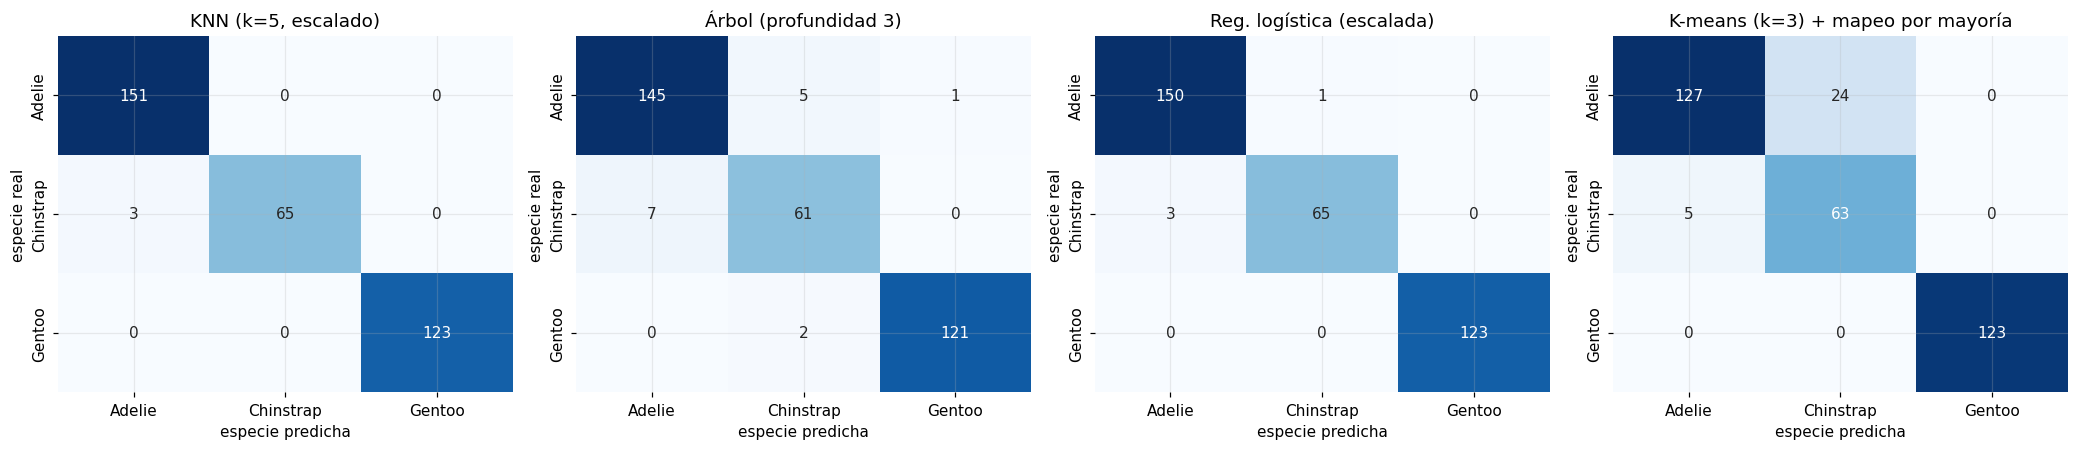

In [73]:
etiquetas_sp = sorted(set(y_sp))
nombres_mostrar = ["KNN (k=5, escalado)", "Árbol (profundidad 3)", "Reg. logística (escalada)",
                   "K-means (k=3) + mapeo por mayoría"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, nombre in zip(axes, nombres_mostrar):
    cm = confusion_matrix(y_sp, predicciones[nombre], labels=etiquetas_sp)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=etiquetas_sp, yticklabels=etiquetas_sp)
    ax.set(title=nombre, xlabel="especie predicha", ylabel="especie real")
plt.tight_layout(); plt.show()

### Interpretabilidad: coeficientes, reglas y centroides

Cada modelo se explica de una forma distinta:

* **Regresión logística:** con **coeficientes** (uno por variable y por clase). Con las variables estandarizadas, un coeficiente positivo grande significa que esa variable, cuando es alta, **aumenta el puntaje** de esa especie.
* **Árbol:** con **reglas** (pregunta tras pregunta sobre una variable a la vez, en direcciones paralelas a los ejes).
* **K-means:** con **centroides** (perfiles promedio); las fronteras son oblicuas (celdas de Voronoi) y no usan la especie.

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,intercepto
Adelie,-2.720,1.535,-0.493,0.379,0.563
Chinstrap,2.364,0.233,-0.711,-1.533,-0.164
Gentoo,0.356,-1.769,1.203,1.154,-0.399


Número de parámetros: 15


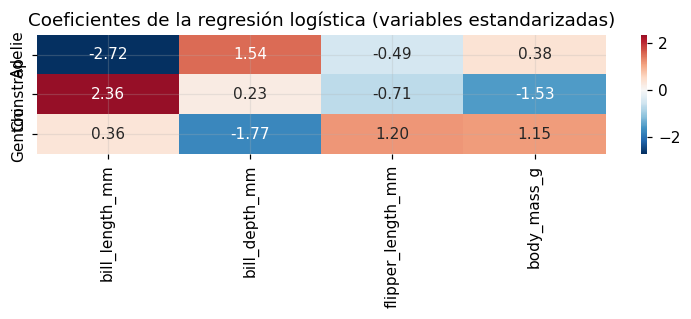

In [75]:
log_final = Pipeline([("esc", StandardScaler()), ("log", LogisticRegression(max_iter=1000))]).fit(X_df, y_sp)
coef = pd.DataFrame(log_final.named_steps["log"].coef_, index=log_final.named_steps["log"].classes_, columns=variables)
coef["intercepto"] = log_final.named_steps["log"].intercept_
display(coef)
print("Número de parámetros:", coef.size)

fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(coef[variables], annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Coeficientes de la regresión logística (variables estandarizadas)")
plt.tight_layout(); plt.show()

|--- flipper_length_mm <= 206.50
|   |--- bill_length_mm <= 43.35
|   |   |--- bill_length_mm <= 42.35
|   |   |   |--- class: Adelie
|   |   |--- bill_length_mm >  42.35
|   |   |   |--- class: Adelie
|   |--- bill_length_mm >  43.35
|   |   |--- body_mass_g <= 4125.00
|   |   |   |--- class: Chinstrap
|   |   |--- body_mass_g >  4125.00
|   |   |   |--- class: Chinstrap
|--- flipper_length_mm >  206.50
|   |--- bill_depth_mm <= 17.65
|   |   |--- class: Gentoo
|   |--- bill_depth_mm >  17.65
|   |   |--- bill_length_mm <= 46.55
|   |   |   |--- class: Adelie
|   |   |--- bill_length_mm >  46.55
|   |   |   |--- class: Chinstrap



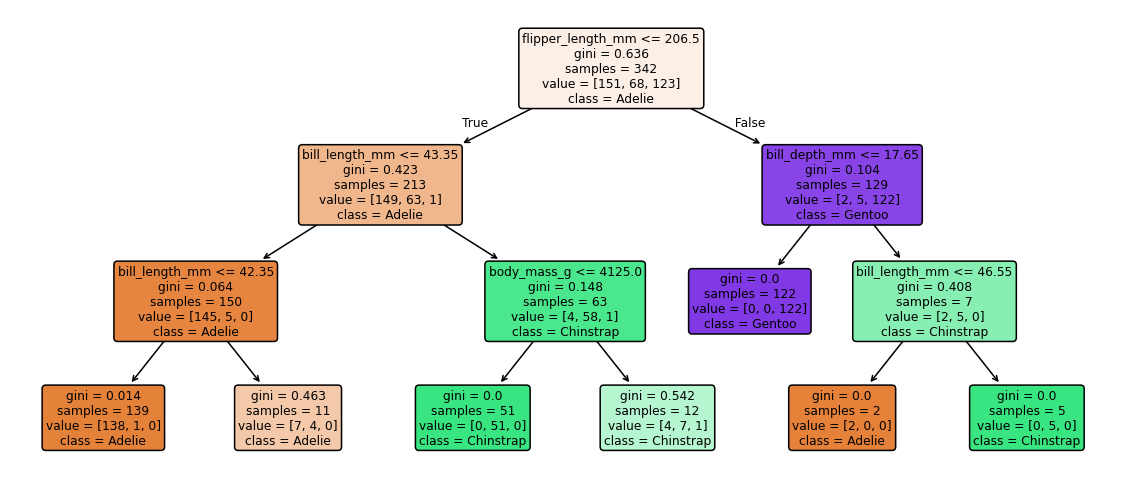

In [77]:
arbol = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_df, y_sp)
print(export_text(arbol, feature_names=variables))

fig, ax = plt.subplots(figsize=(13, 5.5))
plot_tree(arbol, feature_names=variables, class_names=list(arbol.classes_), filled=True, rounded=True, fontsize=8, ax=ax)
plt.show()

### Uso combinado: k-means como generador de variables

Una forma práctica de combinar las dos familias es usar el resultado de k-means como **variables nuevas** para un modelo supervisado, por ejemplo las **distancias a los $k$ centroides**. El `FeatureUnion` de abajo ajusta k-means **dentro de cada partición de entrenamiento** (sin ver los datos de prueba), de modo que no hay fuga de información.

In [79]:
from sklearn.pipeline import FeatureUnion

arbol_solo = DecisionTreeClassifier(max_depth=3, random_state=SEED)
arbol_con_km = Pipeline([
    ("esc", StandardScaler()),
    ("variables", FeatureUnion([("originales", "passthrough"),
                                ("dist_centroides", KMeans(3, n_init=25, random_state=SEED))])),
    ("arbol", DecisionTreeClassifier(max_depth=3, random_state=SEED)),
])
extra = {}
for nombre, m in {"Árbol solo": arbol_solo, "Árbol + distancias a centroides de k-means": arbol_con_km}.items():
    pred = cv_predicciones_supervisado(m)
    extra[nombre] = dict(accuracy=accuracy_score(y_sp, pred), F1_macro=f1_score(y_sp, pred, average="macro"),
                         ARI=adjusted_rand_score(y_sp, pred))
display(pd.DataFrame(extra).T)

,accuracy,F1_macro,ARI
Árbol solo,0.956,0.947,0.884
Árbol + distancias a centroides de k-means,0.962,0.953,0.901


> **Lectura.**
> * **Valor de las etiquetas.** Los tres modelos supervisados superan a k-means: KNN escalado (accuracy ≈ 0.99) y la regresión logística (≈ 0.99) quedan casi empatados, el árbol (≈ 0.96) un poco por debajo, y k-means, que nunca vio la especie, llega a ≈ 0.92 aun con el mapeo. La brecha es lo que aportan las etiquetas.
> * **Dónde se equivocan.** La logística comete solo 4 errores (1 *Adelie* clasificado como *Chinstrap* y 3 *Chinstrap* como *Adelie*); KNN, 3; el árbol, 15, casi todos entre *Adelie* y *Chinstrap* (y 3 que involucran a *Gentoo*). K-means separa *Gentoo* sin ningún error, pero mezcla 24 *Adelie* en el grupo de los *Chinstrap* (sobre todo machos, como vimos en §3.9): no tiene forma de saber que esos pingüinos son de otra especie porque solo mira medidas.
> * **Paramétrico frente a no paramétrico.** La regresión logística resume todo en **15 números** y rinde casi igual que KNN, que guarda los 342 pingüinos. Cuando la estructura es casi lineal, un modelo paramétrico simple basta; las reglas del árbol, paralelas a los ejes, tienen que aproximar con varios cortes una frontera que es oblicua. Es coherente con que k-means, también con fronteras lineales, se defienda razonablemente bien.
> * **Escalado.** KNN sin escalar cae a ≈ 0.79, igual que k-means sin escalar en §3.10; el árbol no lo necesita. La logística sin escalar da **las mismas predicciones** en estos datos porque aprende un coeficiente por variable, **pero el optimizador no converge** (ver el aviso de la celda): el resultado no es confiable en general. Escalar sigue siendo la práctica correcta.
> * **Interpretación.** Los coeficientes de la logística (variables estandarizadas) cuentan una historia coherente con el perfilado de k-means: *Gentoo* se asocia a picos poco profundos, aletas largas y gran masa; *Chinstrap*, a picos largos y menor masa; *Adelie*, a picos cortos. El árbol se explica con reglas (la primera pregunta es la longitud de la aleta) y k-means con perfiles promedio. El árbol y la logística responden "¿qué especie es?"; k-means responde "¿qué pingüinos se parecen?".
> * **Uso combinado.** Añadir las distancias a los centroides de k-means casi no cambia al árbol (0.962 frente a 0.956, una diferencia de apenas unos pocos pingüinos que no es concluyente con un solo experimento de 5 particiones). Aquí no aporta información nueva porque las variables originales ya son informativas, pero la idea es útil cuando hay muchas variables o estructura no lineal.
> * **Conclusión.** Si hay etiquetas y el objetivo es **predecir**, use un modelo supervisado. Si no hay etiquetas o se busca **descubrir y describir estructura**, use clustering. Compararlos sirve para entender qué información aporta cada enfoque, no para declarar un ganador.

## Conclusiones

**Lo que encontramos.** Solo con cuatro medidas corporales, k-means identifica tres grupos de pingüinos que corresponden en gran medida a las tres especies, con la mayor separación entre *Gentoo* (más grandes, picos menos profundos y aletas largas) y las otras dos. La decisión de $k$ no fue trivial: distintos criterios sugieren $k=2$ o $k=3$.

**Limitaciones.**
* K-means supone grupos aproximadamente esféricos y de tamaño similar; el solapamiento entre *Adelie* y *Chinstrap* y el dimorfismo sexual lo ponen a prueba.
* Siempre devuelve $k$ grupos, haya o no estructura real: la validez hay que **demostrarla** (criterios internos, estabilidad, sentido en el dominio).
* Los resultados dependen de la escala, de las variables escogidas y de la distancia.
* Con datos reales rara vez existe una etiqueta de referencia como la especie.

**Lista de verificación al aplicar k-means a un problema real**

| ✔ | Paso | Pregunta de control |
|---|---|---|
| ☐ | Datos faltantes y duplicados | ¿Los eliminé o imputé con criterio (sin fabricar estructura)? |
| ☐ | Variables | ¿Son numéricas y relevantes? ¿Hay redundancia (alta correlación) o categóricas mal codificadas? |
| ☐ | Atípicos y asimetría | ¿Hay valores extremos que arrastren centroides? ¿Conviene una transformación (por ejemplo, logarítmica en variables de dinero)? |
| ☐ | Escalado | ¿Estandaricé con parámetros guardados del entrenamiento? |
| ☐ | Elección de $k$ | ¿Usé varios criterios (codo, silueta, gap, CH, DB) y el sentido del problema? |
| ☐ | Inicialización | ¿k-means++, `n_init` ≥ 10 y `random_state` fijo? |
| ☐ | Estabilidad | ¿Los grupos se sostienen con remuestreo? |
| ☐ | Interpretación | ¿Perfilé los grupos en unidades originales y les di sentido junto con expertos? |
| ☐ | Validación | ¿Usé métricas internas y, si existe, referencia externa? |
| ☐ | Despliegue | ¿Guardé el `Pipeline` completo? ¿Monitoreo atípicos y deriva en datos nuevos? |

**Para seguir practicando.** Repita el análisis con otro conjunto de datos real, por ejemplo *Wholesale customers* (UCI Machine Learning Repository: gasto anual de clientes de un distribuidor mayorista en seis categorías de producto). Allí las variables de gasto son muy asimétricas, por lo que conviene probar una **transformación logarítmica** antes de escalar, y comparar los resultados con la columna `Channel` como referencia externa.

**Referencias.** Gorman, K. B., Williams, T. D. y Fraser, W. R. (2014), *Ecological sexual dimorphism and environmental variability within a community of Antarctic penguins*, PLoS ONE. Horst, A. M., Hill, A. P. y Gorman, K. B. (2020), *palmerpenguins* (paquete de R). Arthur, D. y Vassilvitskii, S. (2007), *k-means++: the advantages of careful seeding*. Rousseeuw, P. J. (1987), *Silhouettes*. Tibshirani, R., Walther, G. y Hastie, T. (2001), *Estimating the number of clusters in a data set via the gap statistic*.